# 05 // Alpha diversity analysis

This notebook:

* Calculates alpha diversity (richness and evenness) for each sample and compares it across the four urbanization levels: Urban, Peri-urban, Peri-rural and Hinterland (= rural).
* Tests associations with age and with technical variables (read depth, % classified reads), and adjusts the urbanization effect for % classified and age.
* Checks the robustness with sensitivity analyses (without flagged samples, all organisms, genus level, a higher rarefying depth) and compares species and genus level.

Beta diversity is not part of this notebook. We use QIIME 2 for filtering, rarefying and alpha diversity, and pandas, scipy, statsmodels, matplotlib and seaborn for statistics and figures.

| Metric | What it measures |
|---|---|
| Observed features | Number of taxa detected (richness) |
| Shannon entropy | Richness and evenness together |
| Simpson index (1 − D) | Probability that two random read pairs belong to different taxa; weights abundant taxa |
| Pielou's evenness | Shannon relative to richness (0–1) |

Tests: Kruskal-Wallis with pairwise Mann-Whitney tests (BH-corrected), Spearman correlation, and linear models with robust standard errors. Faith's PD and q2-kmerizer are not applicable (no phylogeny, no representative sequences).

Important considerations:

* The tables contain **read-pair counts estimated by Bracken for classified reads only**. The classified fraction differs between levels (median 58% Urban, 60% Peri-urban, 43% Peri-rural, 48% Hinterland), so diversity could differ for technical reasons (sections 7–8).
* **Urbanization is confounded with country, study and sequencing batch** (each level comes from one country, except Peri-urban: Cameroon and Tanzania). All results are statistical associations, not causal effects.
* The tables contain bacteria, archaea, viruses and fungi; section 2 decides what counts as "diversity". Leftover human reads (Hominidae) are removed. Flagged samples from notebooks 01–04 are kept (checked in section 9).

Inputs: `results/04_taxonomy/bracken_table_{S,G}.qza` and `bracken_taxonomy_{S,G}.qza` (species and genus level), `african_gut_microbiomes_metadata.tsv`, `results/04_read_tracking.tsv`.

Outputs (in `results/`): `05_alpha_diversity/` (QIIME 2 artifacts), `05_alpha_diversity_values.tsv`, statistical tables (`05_*.tsv`) and figures (`05_*.png`).

The input files are hashed; if they change, the notebook stops so that old results are not reused (delete `results/05_alpha_diversity/` to start again). The Notes describe the current data.

## Setup

In [41]:
%matplotlib inline
import hashlib
import json
import os
import re
import shutil
import subprocess
import sys
import zipfile
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from matplotlib.patches import Patch
from scipy import stats
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multitest import multipletests
from qiime2 import Artifact, Metadata, Visualization

# Work from the repository root (this notebook is one level inside it, in notebooks/)
if Path.cwd().name == "notebooks":
    os.chdir("..")
print("Working directory:", Path.cwd())

# This makes qiime available to the commands we run below
os.environ["PATH"] = str(Path(sys.executable).parent) + os.pathsep + os.environ["PATH"]

RESULTS = Path("results")
TAXONOMY_DIR = RESULTS / "04_taxonomy"
ALPHA_DIR = RESULTS / "05_alpha_diversity"
METADATA_FILE = Path("african_gut_microbiomes_metadata.tsv")

# Several steps reuse existing outputs: stop if the input files have changed since the previous run
INPUT_FILES = ([TAXONOMY_DIR / f"bracken_{kind}_{level}.qza" for kind in ["table", "taxonomy"] for level in ["S", "G"]]
               + [METADATA_FILE, RESULTS / "04_read_tracking.tsv"])
fingerprint = {str(path): hashlib.sha256(path.read_bytes()).hexdigest() for path in INPUT_FILES}
fingerprint_file = ALPHA_DIR / "input_fingerprint.json"
if fingerprint_file.exists() and json.loads(fingerprint_file.read_text()) != fingerprint:
    raise RuntimeError(f"Input files have changed since the previous run. Review or remove the old results in {ALPHA_DIR}.")
for sub in ["filtered_tables", "rarefaction", "core_metrics"]:
    (ALPHA_DIR / sub).mkdir(parents=True, exist_ok=True)
fingerprint_file.write_text(json.dumps(fingerprint, indent=2))

SEED = 42   # random seed for rarefying (passed to QIIME 2 in section 5)

# Urbanization levels from most to least urban, and one colour per level (same as in notebooks 01-04)
URBANIZATION_ORDER = ["Urban", "Peri-urban", "Peri-rural", "Hinterland"]
COLOURS = {"Urban": "#2a78d6", "Peri-urban": "#eb6834", "Peri-rural": "#1baf7a", "Hinterland": "#eda100"}
PLOT_LABELS = {"Hinterland": "Rural"}   # in plots, "Hinterland" is labelled "Rural"

def pretty(level):
    return PLOT_LABELS.get(level, level)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})


def run(command):
    # Runs a QIIME 2 command (given as a list) and stops with QIIME's error message if it fails
    result = subprocess.run([str(part) for part in command], capture_output=True, text=True)
    if result.returncode != 0:
        raise RuntimeError(result.stderr)
    print(result.stdout.strip() or "done")

Working directory: /home/jovyan/microbiome


## 1. Sample metadata

We combine the read-tracking table of notebook 04 (country, urbanization, batch, read counts, % classified, QC flags) with age from the original metadata, and look at the sample distribution and at possible confounding.

In [42]:
# Load sample information from the previous notebooks
tracking = pd.read_csv(RESULTS / "04_read_tracking.tsv", sep="\t", index_col="sample_id")
# Load the original sample metadata
raw_metadata = pd.read_csv(METADATA_FILE, sep="\t", index_col="id")

# Check that every sample of the tracking table also has an entry in the raw metadata
assert set(tracking.index) <= set(raw_metadata.index), "Samples missing in the raw metadata"

# Add age to the tracking table
metadata = tracking.join(raw_metadata[["age"]], how="left")

# Check that every sample has complete metadata and that both files agree
assert metadata["age"].notna().all(), "Missing age values"
assert (raw_metadata.loc[tracking.index, "urbanization"] == tracking["urbanization"]).all(), "Urbanization differs between files"
metadata["urbanization"] = pd.Categorical(metadata["urbanization"], categories=URBANIZATION_ORDER)

# Use the standard QIIME 2 sample identifier
metadata.index.name = "sample-id"

# Check that sample identifiers are unique and urbanization values are valid
assert metadata.index.is_unique, "Duplicate sample IDs detected"
assert metadata["urbanization"].notna().all(), "Missing or invalid urbanization categories"

# Number of samples
N_SAMPLES = len(metadata)

print("Samples:", N_SAMPLES)

Samples: 53


In [43]:
# Samples per urbanization level and country (shows the confounding), and age and % classified per level
display(pd.crosstab(metadata["urbanization"], metadata["country_iso3"], margins=True))
(metadata.groupby("urbanization", observed=True)[["age", "pct_classified"]]
         .agg(["count", "median", "min", "max"]).round(1))

country_iso3,CMR,GNB,MDG,TZA,All
urbanization,,,,,
Urban,10,0,0,0,10
Peri-urban,2,0,0,8,10
Peri-rural,0,0,17,0,17
Hinterland,0,16,0,0,16
All,12,16,17,8,53


age                pct_classified                   
             count median min max          count median   min   max
urbanization                                                       
Urban           10   39.5  22  65             10   57.8  27.3  88.3
Peri-urban      10   29.5  19  48             10   59.8  43.6  72.8
Peri-rural      17   33.0  26  58             17   43.4  22.6  66.6
Hinterland      16   25.5  19  60             16   48.1  27.9  66.7

Notes:

* Each urbanization level comes from one country, except Peri-urban (Cameroon n = 2, Tanzania n = 8), so urbanization and country cannot be separated.
* Age: the median is highest in Urban (39.5 years) and lowest in Hinterland (25.5 years); the overall range is 19-65 years.
* % classified: lowest in Peri-rural (median 43.4%) and Hinterland (48.1%), highest in Peri-urban (59.8%) and Urban (57.8%). Because only classified reads enter the tables, it can influence the diversity estimates (sections 7-8).

In [44]:
# Metadata file for QIIME 2 (grouping columns only)
QIIME_METADATA = ALPHA_DIR / "05_qiime_metadata.tsv"
metadata[["country_iso3", "urbanization", "batch"]].to_csv(QIIME_METADATA, sep="\t", index_label="sample-id")
Metadata.load(str(QIIME_METADATA))   # validates the file
print("QIIME 2 metadata loaded successfully.")

QIIME 2 metadata loaded successfully.


## 2. What is in the feature tables?

We check which domains and kingdoms the classified reads belong to, to decide which organisms count as "diversity". The taxonomy of each feature is a lineage (d, k, p, c, o, f, g, s); Eukaryota are split by kingdom.

In [45]:
table_S = Artifact.load(TAXONOMY_DIR / "bracken_table_S.qza").view(pd.DataFrame)   # rows: samples, columns: species (NCBI taxon IDs)
taxonomy_S = Artifact.load(TAXONOMY_DIR / "bracken_taxonomy_S.qza").view(pd.DataFrame)
print("Samples:", table_S.shape[0], "| species:", table_S.shape[1])

assert set(table_S.index) == set(metadata.index), "Samples of the feature table and the metadata differ"
assert set(table_S.columns) <= set(taxonomy_S.index), "Species without taxonomy"

# First rank of every lineage = domain; stop if the expected prefixes are missing
domains = taxonomy_S["Taxon"].map(lambda taxon: taxon.split(";")[0].strip())
print(domains.value_counts().to_string())
assert {"d__Bacteria", "d__Archaea"} <= set(domains), "Unexpected taxonomy format: adjust taxon_group and the filters in section 3"

Samples: 53 | species: 3810
Taxon
d__Bacteria     3301
d__Viruses       437
d__Eukaryota      45
d__Archaea        27


In [46]:
def taxon_group(taxon):
    # Domain of a lineage; for Eukaryota the kingdom instead (Fungi, Metazoa, ...)
    parts = [part.strip() for part in taxon.split(";")]
    domain = parts[0].replace("d__", "")
    if domain == "Eukaryota" and len(parts) > 1:
        return parts[1].replace("k__", "")
    return domain

MAIN_GROUPS = ["Bacteria", "Archaea", "Viruses", "Fungi"]
group_of_feature = taxonomy_S.loc[table_S.columns, "Taxon"].map(taxon_group)
group_of_feature = group_of_feature.where(group_of_feature.isin(MAIN_GROUPS), "Other eukaryotes")

# Read pairs per sample and group, and the share of each group in the classified reads
group_counts = table_S.T.groupby(group_of_feature.values).sum().T
group_share = 100 * group_counts.div(group_counts.sum(axis=1), axis=0)
group_share = group_share.reindex(columns=MAIN_GROUPS + ["Other eukaryotes"]).fillna(0)

# Mean share of the classified reads per urbanization level, and number of species per group
print("Species per group:", group_of_feature.value_counts().to_dict())
(group_share.join(metadata["urbanization"]).groupby("urbanization", observed=True).mean().round(2))

Species per group: {'Bacteria': 3301, 'Viruses': 437, 'Fungi': 37, 'Archaea': 27, 'Other eukaryotes': 8}


,Bacteria,Archaea,Viruses,Fungi,Other eukaryotes
urbanization,,,,,
Urban,99.43,0.06,0.51,0.00,0.00
Peri-urban,99.67,0.10,0.04,0.16,0.03
Peri-rural,94.09,0.41,5.49,0.00,0.00
Hinterland,97.02,2.75,0.23,0.00,0.00


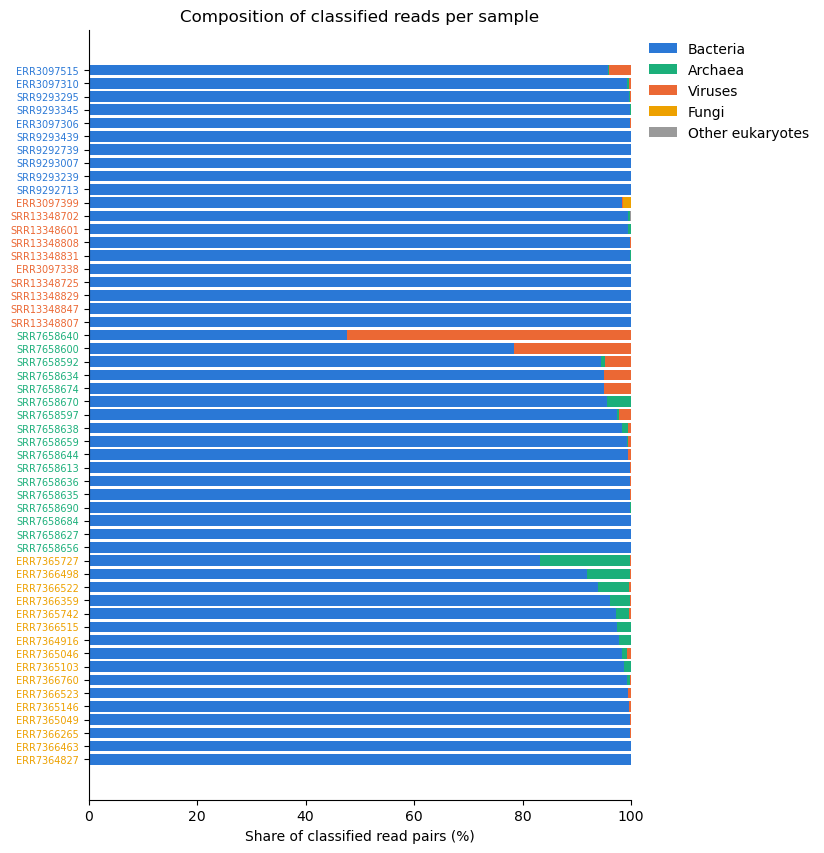

In [47]:
# Stacked bar chart: composition of the classified reads per sample, grouped by urbanization level
group_colours = {"Bacteria": "#2a78d6", "Archaea": "#1baf7a", "Viruses": "#eb6834",
                 "Fungi": "#eda100", "Other eukaryotes": "#9a9a9a"}

# Sort samples by urbanization level and bacterial proportion
plot_data = group_share.join(metadata["urbanization"]).sort_values(["urbanization", "Bacteria"])

fig, ax = plt.subplots(figsize=(7, 10))
left = np.zeros(len(plot_data))

# Plot all organism groups present in the data
for group, colour in group_colours.items():
    ax.barh(plot_data.index, plot_data[group], left=left, color=colour, height=0.8, label=group)
    left += plot_data[group].values
ax.invert_yaxis()                      # first urbanization level at the top
ax.set_xlim(0, 100)
ax.set_xlabel("Share of classified read pairs (%)")
ax.set_title("Composition of classified reads per sample")
ax.tick_params(axis="y", labelsize=7)

# Colour the sample labels by urbanization level
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
for label, level in zip(ax.get_yticklabels(), plot_data["urbanization"]):
    label.set_color(COLOURS[level])
    
fig.savefig(RESULTS / "05_domain_composition.png", dpi=150, bbox_inches="tight")
plt.show()

In [48]:
# Samples with the highest non-bacterial share
non_bacterial = group_share.assign(non_bacterial=100 - group_share["Bacteria"]).join(metadata["urbanization"])
non_bacterial.sort_values("non_bacterial", ascending=False).head(5).round(1)

,Bacteria,Archaea,Viruses,Fungi,Other eukaryotes,non_bacterial,urbanization
SRR7658640,47.7,0.0,52.3,0.0,0.0,52.3,Peri-rural
SRR7658600,78.4,0.0,21.6,0.0,0.0,21.6,Peri-rural
ERR7365727,83.2,16.6,0.2,0.0,0.0,16.8,Hinterland
ERR7366498,91.9,7.9,0.2,0.0,0.0,8.1,Hinterland
ERR7366522,93.8,5.9,0.3,0.0,0.0,6.2,Hinterland


Notes:

* The species table has 3,810 species: 3,301 bacteria, 437 viruses, 45 eukaryotes and 27 archaea. Bacteria dominate the classified reads in all levels (mean 94.1-99.7%).
* The non-bacterial share is driven by a few samples: SRR7658640 (52.3% viral) and SRR7658600 (21.6% viral) in Peri-rural, ERR7365727 (16.6% archaea) and ERR7366498 (7.9% archaea) in Hinterland.
* Viruses and eukaryotes make up about 13% of the features but only 0.2-5.5% of the classified read pairs per level, and viral and eukaryotic assignments from short reads are hard to compare with bacterial ones. **Decision:** the main analysis uses bacteria + archaea (`S_prok`); all organisms (`S_all`) and the genus level (`G_prok`) are sensitivity analyses.

## 3. Filtering the feature tables

| Variant | Level | Taxa | Role |
|---|---|---|---|
| `S_prok` | species | bacteria + archaea | **main analysis** |
| `S_all` | species | all organisms | sensitivity analysis |
| `G_prok` | genus | bacteria + archaea | sensitivity analysis |

In all variants the leftover human reads are removed with `--p-exclude Hominidae` (the family, because "Homo" would also remove the bacterium *Homoserinibacter*).

In [49]:
# Leftover human reads: share of each sample's classified read pairs that are Hominidae
is_hominid = taxonomy_S.loc[table_S.columns, "Taxon"].str.contains("Hominidae").values
hominid_share = 100 * table_S.loc[:, is_hominid].sum(axis=1) / table_S.sum(axis=1)

print("Hominidae features:", taxonomy_S.loc[table_S.columns[is_hominid], "Taxon"].map(lambda t: t.split(";")[-1].strip()).tolist())
print("Samples with Hominidae reads:", int((hominid_share > 0).sum()), "of", len(hominid_share))
print(f"Maximum share in a sample: {hominid_share.max():.3f}%")

Hominidae features: ['s__Homo sapiens']
Samples with Hominidae reads: 50 of 53
Maximum share in a sample: 0.117%


In [50]:
VARIANTS = {
    "S_prok": {"level": "S", "domains": ["d__Bacteria", "d__Archaea"]},
    "S_all":  {"level": "S", "domains": None},
    "G_prok": {"level": "G", "domains": ["d__Bacteria", "d__Archaea"]},
}
MAIN = "S_prok"

# Filtering runs quickly; skipped if the output exists already
for name, variant in VARIANTS.items():
    output = ALPHA_DIR / "filtered_tables" / f"table_{name}.qza"
    if output.exists():
        print(name, "exists already")
        continue
    command = ["qiime", "taxa", "filter-table",
               "--i-table", TAXONOMY_DIR / f"bracken_table_{variant['level']}.qza",
               "--i-taxonomy", TAXONOMY_DIR / f"bracken_taxonomy_{variant['level']}.qza",
               "--p-exclude", "Hominidae"]
    if variant["domains"]:
        command += ["--p-include", ",".join(variant["domains"])]
    run(command + ["--o-filtered-table", output])

S_prok exists already
S_all exists already
G_prok exists already


In [51]:
taxonomies = {level: Artifact.load(TAXONOMY_DIR / f"bracken_taxonomy_{level}.qza").view(pd.DataFrame) for level in ["S", "G"]}
filtered = {name: Artifact.load(ALPHA_DIR / "filtered_tables" / f"table_{name}.qza").view(pd.DataFrame) for name in VARIANTS}
depths = {name: table.sum(axis=1) for name, table in filtered.items()}

rows = []
for name, table in filtered.items():
    variant = VARIANTS[name]
    lineages = taxonomies[variant["level"]].loc[table.columns, "Taxon"]
    assert table.shape[0] == N_SAMPLES, f"{name}: samples were lost"
    assert set(table.index) == set(metadata.index), f"{name}: sample IDs differ from the metadata"
    assert not lineages.str.contains("Hominidae").any(), f"{name}: Hominidae left"
    if variant["domains"]:
        assert lineages.str.startswith(tuple(variant["domains"])).all(), f"{name}: unexpected domains remain"
    rows.append({"variant": name, "samples": table.shape[0], "features": table.shape[1],
                 "min_depth": depths[name].min(), "median_depth": depths[name].median(), "max_depth": depths[name].max()})
pd.DataFrame(rows).set_index("variant").round(0).astype(int)

,samples,features,min_depth,median_depth,max_depth
variant,,,,,
S_prok,53,3328,1491178,7973273,24586456
S_all,53,3809,1494594,7988871,24731919
G_prok,53,1208,1492975,7977574,24597118


In [52]:
# Consistency check of the filtering (all variants): recompute in pandas what must be left in each table
# and compare it with the QIIME 2 result, both the read pairs per sample and the set of features
tables_full = {level: Artifact.load(TAXONOMY_DIR / f"bracken_table_{level}.qza").view(pd.DataFrame) for level in ["S", "G"]}

for name, variant in VARIANTS.items():
    full = tables_full[variant["level"]]
    lineages_full = taxonomies[variant["level"]].loc[full.columns, "Taxon"]
    keep = ~lineages_full.str.contains("Hominidae")
    if variant["domains"]:
        keep &= lineages_full.str.startswith(tuple(variant["domains"]))
    expected_depth = full.loc[:, keep.values].sum(axis=1)
    assert np.allclose(depths[name], expected_depth.reindex(depths[name].index)), f"{name}: read pairs differ from expectation"
    assert set(filtered[name].columns) == set(full.columns[keep.values]), f"{name}: features differ from expectation"
    print(f"{name}: OK ({filtered[name].shape[1]} of {full.shape[1]} features kept)")

# How much of the classified reads is kept when only bacteria + archaea are used?
kept = 100 * depths["S_prok"] / table_S.sum(axis=1)
print("\nShare of the classified read pairs kept in S_prok (%):")
display(kept.describe().round(2))
kept.sort_values().head(5).round(1)

S_prok: OK (3328 of 3810 features kept)
S_all: OK (3809 of 3810 features kept)
G_prok: OK (1208 of 1405 features kept)

Share of the classified read pairs kept in S_prok (%):


count     53.00
mean      98.02
std        7.72
min       47.71
25%       99.54
50%       99.85
75%       99.96
max      100.00
dtype: float64

SRR7658640    47.7
SRR7658600    78.4
SRR7658634    95.0
SRR7658674    95.1
SRR7658592    95.2
dtype: float64

Notes:

* Hominidae (only *Homo sapiens*) are still assigned in 50 of 53 samples, at most 0.117% of a sample's classified read pairs; they are removed in all variants.
* `S_prok` keeps 3,328 species (3,301 bacteria + 27 archaea), `S_all` 3,809 and `G_prok` 1,208 genera. The checks confirm that each table contains exactly the expected features and read pairs.
* Read pairs per sample in `S_prok`: 1.49-24.6 million (median 7.97 million). Bacteria + archaea are a median of 99.85% of the classified read pairs; the samples with a large non-bacterial share lose most (SRR7658640 keeps 47.7%).

## 4. Sampling depth and rarefaction

Alpha diversity, especially richness, depends on the number of reads looked at, and the samples differ a lot in depth. We therefore **rarefy** (subsample without replacement) all samples to the same number of read pairs. As a starting point we use the lowest sample depth, rounded down, so that no sample is dropped. A second, higher depth (`ALT_DEPTH`, the 10th percentile) is used in section 9. To change a depth, edit the dictionary below and delete `results/05_alpha_diversity/core_metrics/`.

In [53]:
# Read pairs in the main table per sample; the lowest samples limit the rarefying depth
lowest = depths[MAIN].sort_values().head(5)
(metadata.loc[lowest.index, ["urbanization", "batch", "pct_classified", "low_depth", "low_classified"]]
         .assign(table_depth=lowest.astype(int)))

,urbanization,batch,pct_classified,low_depth,low_classified,table_depth
SRR7658613,Peri-rural,MDG_101,48.090383,True,False,1491178
SRR7658600,Peri-rural,MDG_101,22.581428,False,True,1612764
SRR7658690,Peri-rural,MDG_101,29.282681,False,True,2162266
ERR3097515,Urban,CMR_126,27.252290,False,True,2270062
SRR9293345,Urban,CMR_126,27.787063,False,True,2414424


In [54]:
# Lowest depth of each table, rounded down to 10,000
RAREFY_DEPTH = {name: int(depth.min() // 10_000 * 10_000) for name, depth in depths.items()}
print(RAREFY_DEPTH)

# How many samples (per urbanization level) and how much of the data stay at different rarefying depths?
# ALT_DEPTH is a higher depth for the sensitivity analysis in section 9 (10th percentile of the depths)
ALT_DEPTH = int(depths[MAIN].quantile(0.10) // 100_000 * 100_000)
assert ALT_DEPTH > RAREFY_DEPTH[MAIN], "ALT_DEPTH must be higher than the main depth: set it by hand"
candidates = sorted({RAREFY_DEPTH[MAIN], ALT_DEPTH, int(depths[MAIN].quantile(0.25) // 100_000 * 100_000)})

rows = []
for depth in candidates:
    retained = depths[MAIN] >= depth
    row = {"depth": depth, "samples_kept": int(retained.sum()),
           "pct_reads_used": 100 * depth * retained.sum() / depths[MAIN].sum()}
    for level in URBANIZATION_ORDER:
        row[pretty(level)] = int((retained & (metadata["urbanization"] == level)).sum())
    rows.append(row)
depth_retention = pd.DataFrame(rows).set_index("depth")
depth_retention.round(1)

{'S_prok': 1490000, 'S_all': 1490000, 'G_prok': 1490000}


,samples_kept,pct_reads_used,Urban,Peri-urban,Peri-rural,Rural
depth,,,,,,
1490000,53,16.5,10,10,17,16
3100000,47,30.4,8,10,13,16
5700000,41,48.7,5,10,10,16


In [55]:
RAREFACTION_MAX = int(round(4 * RAREFY_DEPTH[MAIN], -6))      # a few times our chosen depth
rarefaction_qzv = ALPHA_DIR / "rarefaction" / f"alpha_rarefaction_{MAIN}.qzv"

if rarefaction_qzv.exists():
    print("Rarefaction curves exist already:", rarefaction_qzv)
else:
    run(["qiime", "diversity", "alpha-rarefaction",
         "--i-table", ALPHA_DIR / "filtered_tables" / f"table_{MAIN}.qza",
         "--m-metadata-file", QIIME_METADATA,
         "--p-min-depth", 10_000,
         "--p-max-depth", RAREFACTION_MAX,
         "--p-steps", 10,
         "--p-iterations", 5,
         "--p-metrics", "observed_features",
         "--p-metrics", "shannon",
         "--p-metrics", "simpson",
         "--o-visualization", rarefaction_qzv])

Visualization.load(rarefaction_qzv)

Rarefaction curves exist already: results/05_alpha_diversity/rarefaction/alpha_rarefaction_S_prok.qzv


<visualization: Visualization uuid: 7afac870-3b6f-4aeb-82b5-fe7d1f3de5b3>

In [56]:
def rarefaction_plateau(qzv, metrics=("observed_features", "shannon", "simpson")):
    # Median fraction of the value at the highest depth that is already reached at each lower depth
    # (same samples only: those that still have reads at the highest depth)
    rows = {}
    with zipfile.ZipFile(qzv) as archive:
        for metric in metrics:
            name = [n for n in archive.namelist() if n.endswith(f"data/{metric}.csv")][0]
            table = pd.read_csv(archive.open(name), index_col=0)
            columns = [c for c in table.columns if c.startswith("depth-")]
            depths_in_plot = sorted({int(re.match(r"depth-(\d+)_", c).group(1)) for c in columns})
            mean = pd.DataFrame({d: table[[c for c in columns if c.startswith(f"depth-{d}_")]].mean(axis=1)
                                 for d in depths_in_plot})
            present = mean[depths_in_plot[-1]].notna()
            rows[metric] = mean.loc[present].div(mean.loc[present, depths_in_plot[-1]], axis=0).median()
    return pd.DataFrame(rows).rename_axis("depth")


rarefaction_plateau(rarefaction_qzv).round(3)

,observed_features,shannon,simpson
depth,,,
10000,0.364,0.992,1.0
675555,0.951,1.000,1.0
1341111,0.988,1.000,1.0
2006666,0.996,1.000,1.0
2672222,0.999,1.000,1.0
3337777,0.999,1.000,1.0
4003333,1.000,1.000,1.0
4668888,1.000,1.000,1.0
5334444,1.000,1.000,1.0


Notes:

* The lowest sample is SRR7658613 (1,491,178 read pairs, flagged for low depth in notebook 01); four of the five lowest samples also have a low classification rate (22-29%).
* Shannon and Simpson reach at least 99% of their final value at 10,000 read pairs; observed features is the most depth-sensitive metric (36% at 10,000, 95% at 0.7 million, 98.8% at 1.3 million, 99.6% at 2.0 million). The group lines in the interactive plot jump at high depths because samples with fewer read pairs drop out of the group median; this is not a change in diversity.
* **Decision:** we rarefy to **1,490,000 read pairs**, which keeps all 53 samples and all levels at full size (10 / 10 / 17 / 16) but uses only 16.5% of the read pairs. A higher depth drops samples: at 3.1 million 6 (2 Urban, 4 Peri-rural), at 5.7 million 12 (5 Urban, 7 Peri-rural). Section 9 repeats the analysis at 3.1 million.

## 5. Calculating alpha diversity

`qiime diversity core-metrics` rarefies each table once (fixed seed) and calculates observed features, Shannon entropy and Pielou's evenness; Simpson is added with `qiime diversity alpha`. (`core-metrics` also writes beta diversity files, which are not used here.)

In [57]:
def calculate_alpha(name, table_file, depth, seed=SEED):
    # Rarefies a table once to the given depth (fixed seed, default SEED) and calculates the four alpha diversity metrics
    out_dir = ALPHA_DIR / "core_metrics" / name
    if not (out_dir / "rarefied_table.qza").exists():
        # core-metrics needs a new output folder, so remove the leftover of an unfinished run first
        if out_dir.exists():
            shutil.rmtree(out_dir)
        run(["qiime", "diversity", "core-metrics",
             "--i-table", table_file,
             "--p-sampling-depth", depth,
             "--m-metadata-file", QIIME_METADATA,
             "--p-random-seed", seed,
             "--output-dir", out_dir])
    if not (out_dir / "simpson_vector.qza").exists():
        run(["qiime", "diversity", "alpha",
             "--i-table", out_dir / "rarefied_table.qza",
             "--p-metric", "simpson",
             "--o-alpha-diversity", out_dir / "simpson_vector.qza"])
    print(name, f"done (rarefied to {depth:,} read pairs)")


for name in VARIANTS:
    calculate_alpha(name, ALPHA_DIR / "filtered_tables" / f"table_{name}.qza", RAREFY_DEPTH[name])

# Every rarefied table must have exactly the chosen depth in every sample
for name in VARIANTS:
    rarefied = Artifact.load(ALPHA_DIR / "core_metrics" / name / "rarefied_table.qza").view(pd.DataFrame)
    assert (rarefied.sum(axis=1) == RAREFY_DEPTH[name]).all(), f"{name}: samples not at the rarefying depth"
print("All samples rarefied to exactly the chosen depth")

S_prok done (rarefied to 1,490,000 read pairs)
S_all done (rarefied to 1,490,000 read pairs)
G_prok done (rarefied to 1,490,000 read pairs)
All samples rarefied to exactly the chosen depth


In [58]:
# Load all alpha diversity vectors into one table per variant, together with the metadata
METRICS = {"observed_features": "observed_features_vector", "shannon": "shannon_vector",
           "pielou_e": "evenness_vector", "simpson": "simpson_vector"}
METRIC_LABELS = {"observed_features": "Observed features", "shannon": "Shannon entropy",
                 "pielou_e": "Pielou's evenness", "simpson": "Simpson index (1 - D)"}

def load_alpha(name, table_depths):
    # All alpha diversity vectors of one run in one table, together with the metadata
    vectors = {metric: Artifact.load(ALPHA_DIR / "core_metrics" / name / f"{file}.qza").view(pd.Series)
               for metric, file in METRICS.items()}
    values = pd.concat(vectors, axis=1)
    values["table_depth"] = table_depths
    return values.join(metadata)


alpha = {}
for name in VARIANTS:
    alpha[name] = load_alpha(name, depths[name])
    assert len(alpha[name]) == N_SAMPLES, f"{name}: samples lost while rarefying"

# All values in one file
(pd.concat({name: table[list(METRICS) + ["table_depth"]] for name, table in alpha.items()}, names=["variant", "sample_id"])
   .reset_index().to_csv(RESULTS / "05_alpha_diversity_values.tsv", sep="\t", index=False))

data = alpha[MAIN]          # the main analysis
data[list(METRICS)].describe().round(2)

,observed_features,shannon,pielou_e,simpson
count,53.00,53.00,53.00,53.00
mean,591.83,4.07,0.45,0.79
std,196.52,1.10,0.12,0.16
min,310.00,1.22,0.15,0.28
25%,433.00,3.07,0.35,0.68
50%,591.00,4.13,0.47,0.84
75%,706.00,4.95,0.54,0.92
max,1304.00,5.80,0.65,0.96


In [59]:
# Median (and range) per urbanization level, and similarity of the metrics (Spearman correlation across samples)
display(data.groupby("urbanization", observed=True)[list(METRICS)].agg(["median", "min", "max"]).round(2))
data[list(METRICS)].corr(method="spearman").round(2)

observed_features            shannon             pielou_e        \
                        median  min   max  median   min   max   median   min   
urbanization                                                                   
Urban                    403.0  319   484    3.34  1.22  5.80     0.39  0.15   
Peri-urban               458.5  373   565    3.54  2.08  5.74     0.40  0.24   
Peri-rural               706.0  310  1304    3.97  2.47  5.31     0.42  0.24   
Hinterland               679.0  539   874    4.76  3.18  5.71     0.50  0.35   

                   simpson              
               max  median   min   max  
urbanization                            
Urban         0.65    0.75  0.28  0.96  
Peri-urban    0.64    0.74  0.41  0.96  
Peri-rural    0.58    0.81  0.48  0.94  
Hinterland    0.60    0.91  0.68  0.96

,observed_features,shannon,pielou_e,simpson
observed_features,1.00,0.25,0.09,0.23
shannon,0.25,1.00,0.98,0.97
pielou_e,0.09,0.98,1.00,0.96
simpson,0.23,0.97,0.96,1.00


Notes:

* Main analysis (`S_prok`): observed features 310-1,304 (median 591), Shannon 1.22-5.80 (median 4.13), Simpson 0.28-0.96 (median 0.84), Pielou 0.15-0.65 (median 0.47).
* Hinterland has the highest Shannon (4.76), Simpson (0.91) and evenness (0.50); Peri-rural has the highest median richness (706, Hinterland 679); Urban has the lowest richness (403) and Shannon (3.34). The ranges within groups overlap strongly (Urban Shannon 1.22-5.80).
* Shannon, Simpson and Pielou are strongly correlated (rho 0.96-0.98), observed features only weakly with them (rho 0.09-0.25): richness and evenness are separate signals, and the three evenness-related metrics are not independent evidence.

## 6. Alpha diversity across urbanization levels

Because the groups are small and normality cannot be assumed, we use the **Kruskal-Wallis test** for the overall difference and pairwise **Mann-Whitney U tests** as post-hoc tests. P-values are corrected with Benjamini-Hochberg (q-values): over the four metrics for Kruskal-Wallis, and over the six pairs per metric for the pairwise tests. Effect sizes: epsilon-squared = H / (n − 1) (Tomczak & Tomczak, 2014) and, for pairs, the rank-biserial correlation r = 2U / (n1 · n2) − 1 (positive: group 1 has the higher values).

In [60]:
def kruskal_table(table, metrics, group_col="urbanization", levels=URBANIZATION_ORDER):
    # Kruskal-Wallis test of each metric between the groups of a column, BH-corrected over the metrics
    rows = []
    for metric in metrics:
        groups = [table.loc[table[group_col] == level, metric].dropna() for level in levels]
        h, p = stats.kruskal(*groups)
        n = sum(len(group) for group in groups)
        rows.append({"metric": metric, "n": n, "H": h, "p": p,
                     "epsilon_squared": h / (n - 1)})
    result = pd.DataFrame(rows).set_index("metric")
    result["q_bh"] = multipletests(result["p"], method="fdr_bh")[1]
    return result


def pairwise_table(table, metrics, group_col="urbanization", levels=URBANIZATION_ORDER):
    # Pairwise Mann-Whitney U tests between all pairs of groups, BH-corrected within each metric
    rows = []
    for metric in metrics:
        for a, b in combinations(levels, 2):
            x = table.loc[table[group_col] == a, metric].dropna()
            y = table.loc[table[group_col] == b, metric].dropna()
            u, p = stats.mannwhitneyu(x, y, alternative="two-sided")
            rows.append({"metric": metric, "group_1": a, "group_2": b, "n_1": len(x), "n_2": len(y),
                         "median_1": x.median(), "median_2": y.median(), "U": u,
                         "rank_biserial_r": 2 * u / (len(x) * len(y)) - 1, "p": p})
    result = pd.DataFrame(rows)
    result["q_bh"] = result.groupby("metric")["p"].transform(lambda p: multipletests(p, method="fdr_bh")[1])
    return result

In [61]:
kruskal_main = kruskal_table(data, list(METRICS))
pairwise_main = pairwise_table(data, list(METRICS))
display(kruskal_main.round(4))
pairwise_main.round(4)

,n,H,p,epsilon_squared,q_bh
metric,,,,,
observed_features,53,28.1205,0.0000,0.5408,0.0000
shannon,53,6.5775,0.0867,0.1265,0.1155
pielou_e,53,4.0113,0.2602,0.0771,0.2602
simpson,53,8.7564,0.0327,0.1684,0.0654


,metric,group_1,group_2,n_1,n_2,median_1,median_2,U,rank_biserial_r,p,q_bh
0,observed_features,Urban,Peri-urban,10,10,403.0000,458.5000,21.5,-0.5700,0.0342,0.0411
1,observed_features,Urban,Peri-rural,10,17,403.0000,706.0000,18.0,-0.7882,0.0008,0.0017
2,observed_features,Urban,Hinterland,10,16,403.0000,679.0000,0.0,-1.0000,0.0000,0.0001
3,observed_features,Peri-urban,Peri-rural,10,17,458.5000,706.0000,26.0,-0.6941,0.0033,0.0050
4,observed_features,Peri-urban,Hinterland,10,16,458.5000,679.0000,2.0,-0.9750,0.0000,0.0001
5,observed_features,Peri-rural,Hinterland,17,16,706.0000,679.0000,150.0,0.1029,0.6267,0.6267
6,shannon,Urban,Peri-urban,10,10,3.3413,3.5438,46.0,-0.0800,0.7913,0.9001
7,shannon,Urban,Peri-rural,10,17,3.3413,3.9741,70.0,-0.1765,0.4666,0.6999
8,shannon,Urban,Hinterland,10,16,3.3413,4.7588,44.0,-0.4500,0.0613,0.1840
9,shannon,Peri-urban,Peri-rural,10,17,3.5438,3.9741,82.0,-0.0353,0.9001,0.9001


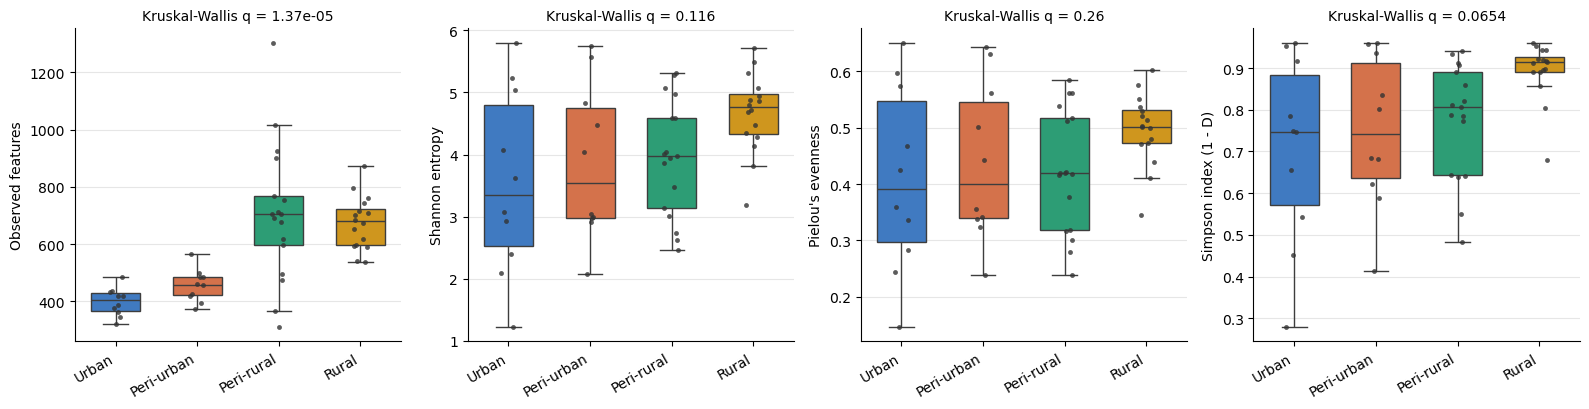

In [62]:
def boxplot_urbanization(ax, table, metric, title=None):
    # Box plot of one metric per urbanization level, with the individual samples
    sns.boxplot(data=table, x="urbanization", y=metric, order=URBANIZATION_ORDER,
                hue="urbanization", hue_order=URBANIZATION_ORDER, palette=COLOURS,
                width=0.6, showfliers=False, legend=False, ax=ax)
    sns.stripplot(data=table, x="urbanization", y=metric, order=URBANIZATION_ORDER,
                  color="0.2", size=3.5, alpha=0.8, ax=ax)
    ax.set_xticks(range(len(URBANIZATION_ORDER)))
    ax.set_xticklabels([pretty(level) for level in URBANIZATION_ORDER], rotation=30, ha="right")
    ax.set_xlabel("")
    ax.set_ylabel(METRIC_LABELS[metric])
    ax.set_title(title, fontsize=10)
    ax.grid(axis="y", color="0.9")
    ax.set_axisbelow(True)


# Box plots of each metric per urbanization level
fig, axes = plt.subplots(1, len(METRICS), figsize=(4 * len(METRICS), 4.2))
for ax, metric in zip(axes, METRICS):
    boxplot_urbanization(ax, data, metric, f"Kruskal-Wallis q = {kruskal_main.loc[metric, 'q_bh']:.3g}")
fig.tight_layout()

fig.savefig(RESULTS / "05_alpha_by_urbanization.png", dpi=150, bbox_inches="tight")
plt.show()

Because urbanization is confounded with country, we also look at the values per **country**, and we check in Guinea-Bissau (the only country with two read lengths) whether read length alone changes alpha diversity.

observed_features  shannon
country_iso3 urbanization                            
CMR          Urban                     403.0     3.34
             Peri-urban                423.0     2.53
GNB          Hinterland                679.0     4.76
MDG          Peri-rural                706.0     3.97
TZA          Peri-urban                472.5     4.26

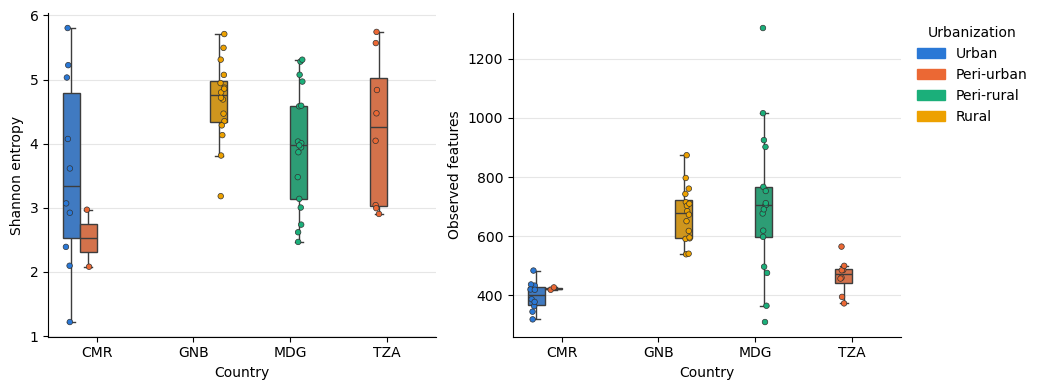

In [63]:
display(data.groupby(["country_iso3", "urbanization"], observed=True)[["observed_features", "shannon"]].median().round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, metric in zip(axes, ["shannon", "observed_features"]):
    sns.boxplot(data=data, x="country_iso3", y=metric, hue="urbanization", hue_order=URBANIZATION_ORDER,
                palette=COLOURS, width=0.7, showfliers=False, legend=False, ax=ax)
    sns.stripplot(data=data, x="country_iso3", y=metric, hue="urbanization", hue_order=URBANIZATION_ORDER,
                  palette=COLOURS, dodge=True, size=4, edgecolor="0.2", linewidth=0.5, legend=False, ax=ax)
    ax.set_xlabel("Country")
    ax.set_ylabel(METRIC_LABELS[metric])
    ax.grid(axis="y", color="0.9")
    ax.set_axisbelow(True)
axes[1].legend(handles=[Patch(color=c, label=pretty(level)) for level, c in COLOURS.items()],
               title="Urbanization", frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))

fig.savefig(RESULTS / "05_alpha_by_country.png", dpi=150, bbox_inches="tight")
plt.show()

In [64]:
# Within Guinea-Bissau (one urbanization level, two sequencing setups): does the batch alone change alpha diversity?
gnb = data[data["country_iso3"] == "GNB"]
rows = []
for metric in METRICS:
    short = gnb.loc[gnb["batch"] == "GNB_101", metric]
    long = gnb.loc[gnb["batch"] == "GNB_151", metric]
    u, p = stats.mannwhitneyu(short, long, alternative="two-sided")
    rows.append({"metric": metric, "n_101": len(short), "n_151": len(long),
                 "median_101": short.median(), "median_151": long.median(), "p": p})
pd.DataFrame(rows).set_index("metric").round(4)

,n_101,n_151,median_101,median_151,p
metric,,,,,
observed_features,6,10,697.0000,679.0000,0.3132
shannon,6,10,4.7826,4.7588,0.9578
pielou_e,6,10,0.5004,0.5079,0.7128
simpson,6,10,0.9043,0.9136,0.7128


Notes:

* **Richness differs strongly between levels** (Kruskal-Wallis H = 28.1, q < 0.0001, epsilon-squared = 0.54): Urban (median 403) < Peri-urban (458.5) < Peri-rural (706) ≈ Hinterland (679). All pairs differ (q = 0.0001-0.041) except Peri-rural vs Hinterland (q = 0.63); Urban and Hinterland are completely separated (r = -1).
* **Evenness-related metrics do not differ significantly:** Shannon q = 0.116, Pielou q = 0.26, Simpson q = 0.065, and no pairwise Shannon comparison has q < 0.05. Only Simpson Peri-rural vs Hinterland (q = 0.022) is significant, which we regard as weak evidence. This depends on the analysis choices (section 9).
* **Richness follows the country:** Cameroon has the lowest richness (Urban median 403; the two Peri-urban samples 423), then Tanzania (Peri-urban 472.5), then Guinea-Bissau (Hinterland 679) and Madagascar (Peri-rural 706). The Urban vs Peri-urban difference therefore mixes level and country. In Guinea-Bissau, samples with 101 bp (n = 6) and 151 bp reads (n = 10) have similar alpha diversity (observed features 697 vs 679, Shannon 4.78 vs 4.76; p >= 0.31); we see no effect of read length alone, but the groups are small. All results are associations, not causal effects.

## 7. Associations with age and with technical variables

Spearman rank correlation of alpha diversity with **age**, **% classified** (of host-free read pairs) and the **read pairs in the table before rarefying**. After rarefying all samples have the same depth, so a correlation with the original depth can reflect a rarefying depth that is too low, but also differences between countries or studies, or classification rates; it is a reason to look closer, not a conclusion. The correlations are also computed within each urbanization level, because the groups differ in age, depth and classification rate.

In [65]:
CONTINUOUS = {"age": "Age (years)", "pct_classified": "Classified read pairs (%)", "table_depth": "Read pairs in table (log scale)"}


def spearman_table(table, metrics, covariates):
    # Spearman correlation of each metric with each covariate, BH-corrected over all tests of the call
    rows = []
    for metric in metrics:
        for covariate in covariates:
            pair = table[[metric, covariate]].dropna()
            rho, p = stats.spearmanr(pair[metric], pair[covariate])
            rows.append({"metric": metric, "covariate": covariate, "n": len(pair), "rho": rho, "p": p})
    result = pd.DataFrame(rows)
    result["q_bh"] = multipletests(result["p"], method="fdr_bh")[1]
    return result


spearman_main = spearman_table(data, list(METRICS), list(CONTINUOUS))
spearman_main.round(4)

,metric,covariate,n,rho,p,q_bh
0,observed_features,age,53,-0.1327,0.3435,0.4122
1,observed_features,pct_classified,53,-0.4782,0.0003,0.0018
2,observed_features,table_depth,53,0.5260,0.0001,0.0006
3,shannon,age,53,-0.1845,0.1860,0.2790
4,shannon,pct_classified,53,-0.4157,0.0020,0.0078
5,shannon,table_depth,53,-0.1000,0.4763,0.5196
6,pielou_e,age,53,-0.1454,0.2988,0.3983
7,pielou_e,pct_classified,53,-0.3702,0.0064,0.0191
8,pielou_e,table_depth,53,-0.2056,0.1397,0.2491
9,simpson,age,53,-0.2028,0.1453,0.2491


In [66]:
# Age within each urbanization level (small groups: low power)
age_within = pd.concat({level: spearman_table(data[data["urbanization"] == level], list(METRICS), ["age"])
                        for level in URBANIZATION_ORDER}, names=["urbanization"]).reset_index(level=0).reset_index(drop=True)
age_within["q_bh_all"] = multipletests(age_within["p"], method="fdr_bh")[1]   # correction over all 16 tests
display(age_within.pivot(index="urbanization", columns="metric", values="rho").reindex(URBANIZATION_ORDER)[list(METRICS)].round(2))
print("Smallest q after correction over the 16 within-group tests:", round(float(age_within["q_bh_all"].min()), 2))

metric,observed_features,shannon,pielou_e,simpson
urbanization,,,,
Urban,-0.08,-0.28,-0.28,-0.27
Peri-urban,0.10,-0.21,-0.14,-0.13
Peri-rural,0.02,-0.01,-0.01,-0.03
Hinterland,-0.22,-0.17,-0.10,-0.19


Smallest q after correction over the 16 within-group tests: 0.98


In [67]:
# % classified and depth within each urbanization level
within_technical = pd.concat({level: spearman_table(data[data["urbanization"] == level], list(METRICS),
                                                    ["pct_classified", "table_depth"])
                              for level in URBANIZATION_ORDER}, names=["urbanization"]).reset_index(level=0).reset_index(drop=True)
within_technical["q_bh_all"] = multipletests(within_technical["p"], method="fdr_bh")[1]   # correction over all 32 tests
within_technical[["urbanization", "metric", "covariate", "rho", "q_bh_all"]].round(3)

,urbanization,metric,covariate,rho,q_bh_all
0,Urban,observed_features,pct_classified,-0.152,0.773
1,Urban,observed_features,table_depth,-0.188,0.715
2,Urban,shannon,pct_classified,-0.382,0.457
3,Urban,shannon,table_depth,-0.345,0.457
4,Urban,pielou_e,pct_classified,-0.382,0.457
5,Urban,pielou_e,table_depth,-0.345,0.457
6,Urban,simpson,pct_classified,-0.345,0.457
7,Urban,simpson,table_depth,-0.309,0.513
8,Peri-urban,observed_features,pct_classified,-0.442,0.457
9,Peri-urban,observed_features,table_depth,0.442,0.457


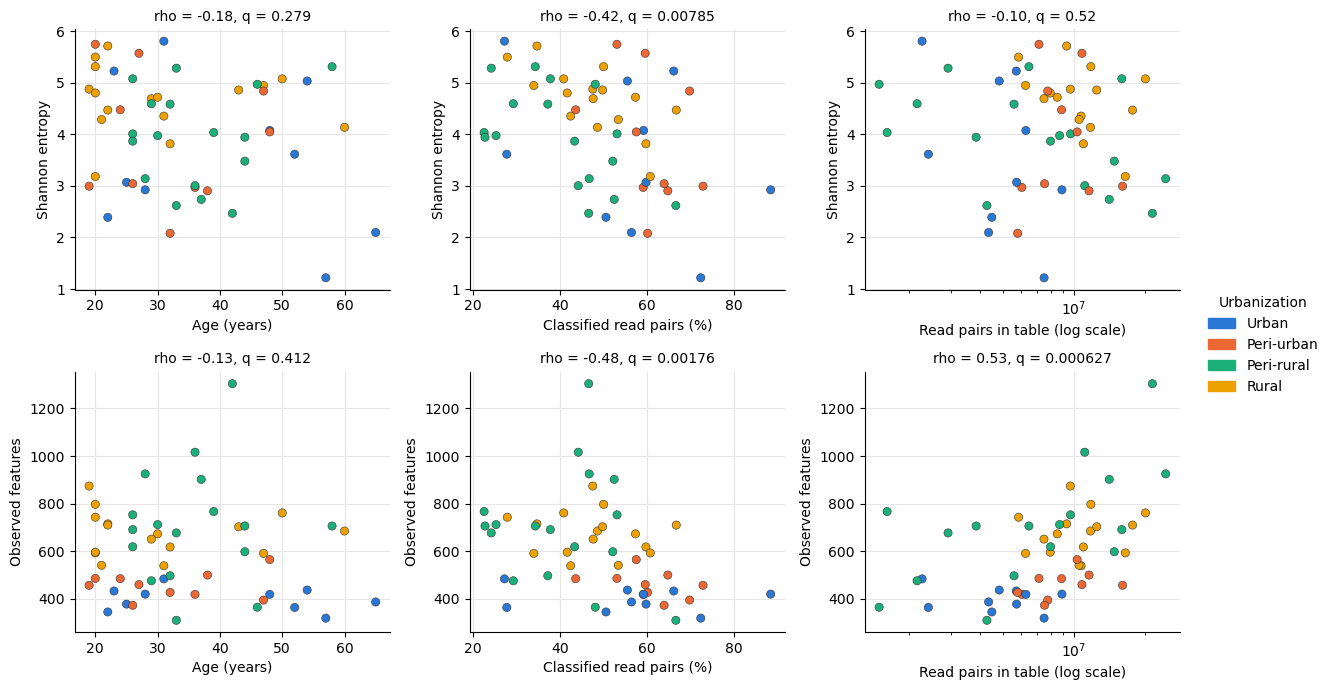

In [68]:
# Alpha diversity against age, % classified and depth, coloured by urbanization level
plot_metrics = ["shannon", "observed_features"]
fig, axes = plt.subplots(len(plot_metrics), len(CONTINUOUS), figsize=(12, 7))
for i, metric in enumerate(plot_metrics):
    for j, (covariate, label) in enumerate(CONTINUOUS.items()):
        ax = axes[i, j]
        sns.scatterplot(data=data, x=covariate, y=metric, hue="urbanization", hue_order=URBANIZATION_ORDER,
                        palette=COLOURS, s=35, edgecolor="0.2", linewidth=0.4, legend=False, ax=ax)
        rho = spearman_main.query("metric == @metric and covariate == @covariate").iloc[0]
        ax.set_title(f"rho = {rho['rho']:.2f}, q = {rho['q_bh']:.3g}", fontsize=10)
        ax.set_xlabel(label)
        ax.set_ylabel(METRIC_LABELS[metric])
        if covariate == "table_depth":
            ax.set_xscale("log")
        ax.grid(color="0.9")
        ax.set_axisbelow(True)
fig.legend(handles=[Patch(color=c, label=pretty(level)) for level, c in COLOURS.items()],
           title="Urbanization", frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5))
fig.tight_layout()

fig.savefig(RESULTS / "05_alpha_vs_covariates.png", dpi=150, bbox_inches="tight")
plt.show()

Notes (q-values in the plot titles: Benjamini-Hochberg over the 12 tests of the overall table):

* **Age** is not associated with any metric, neither over all samples (rho -0.13 to -0.20, q > 0.24) nor within the levels (|rho| <= 0.29, q = 0.98 after correction over 16 tests); with 10-17 samples per group, smaller associations cannot be excluded.
* **% classified** is negatively associated with all four metrics (observed features rho = -0.48, q = 0.0018; Shannon -0.42, q = 0.0078; Pielou -0.37, q = 0.019; Simpson -0.34, q = 0.032), the opposite of an underestimation of diversity at low classification rates. Within the levels all 16 correlations are negative (rho -0.05 to -0.74) but weak for richness (none significant), so the richness correlation mainly reflects the groups. For Shannon, Pielou and Simpson it also appears within groups, clearest in Hinterland (Pielou rho = -0.74, q = 0.038; Shannon -0.70, q = 0.043; Simpson -0.66, q = 0.056 after correction over 32 tests). The cause is unknown; the classified fraction is partly a consequence of the community itself.
* **Read pairs before rarefying** correlate only with observed features (rho = 0.53, q = 0.0006) and not within the levels (strongest in Peri-rural: rho = 0.57, q = 0.105). The deepest samples are mostly Peri-rural, so this fits country and study differences; the higher depth in section 9 is the more direct check.

## 8. Urbanization effect adjusted for % classified and age

A linear model per metric: `alpha ~ urbanization + pct_classified + age`, with Urban as the reference level. Coefficients are differences to Urban at the same % classified and age; standard errors are heteroscedasticity-robust (HC3) because of the small groups, and the joint effect of urbanization is tested with a robust Wald F-test of the three urbanization coefficients. Country, study and batch cannot be added (they are almost collinear with urbanization), so the model is exploratory and only shows whether the urbanization differences remain after accounting for % classified and age.

In [69]:
def adjusted_model(table, metric):
    # OLS with robust (HC3) standard errors and a robust joint Wald test of all urbanization coefficients
    formula = f"{metric} ~ C(urbanization, Treatment('Urban')) + pct_classified + age"
    model = smf.ols(formula, data=table).fit(cov_type="HC3")

    # Joint test: all urbanization coefficients are zero
    names = list(model.params.index)
    terms = [term for term in names if term.startswith("C(urbanization")]
    restrictions = np.zeros((len(terms), len(names)))
    for row, term in enumerate(terms):
        restrictions[row, names.index(term)] = 1
    p_urbanization = float(np.squeeze(model.wald_test(restrictions, use_f=True, scalar=True).pvalue))

    conf = model.conf_int()
    coefficients = pd.DataFrame({"coef": model.params, "ci_low": conf[0], "ci_high": conf[1], "p": model.pvalues})
    coefficients.index = coefficients.index.str.replace(r"C\(urbanization, Treatment\('Urban'\)\)\[T\.(.*)\]",
                                                        r"urbanization: \1", regex=True)
    coefficients.insert(0, "metric", metric)
    coefficients["n"] = int(model.nobs)
    coefficients["p_urbanization_wald"] = p_urbanization
    coefficients["r_squared"] = model.rsquared
    return coefficients


adjusted_models = pd.concat([adjusted_model(data, metric) for metric in METRICS]).rename_axis("term").reset_index()
display(adjusted_models.loc[adjusted_models["term"] != "Intercept", ["metric", "term", "coef", "ci_low", "ci_high", "p"]].round(4))

,metric,term,coef,ci_low,ci_high,p
1,observed_features,urbanization: Peri-urban,61.5307,3.7606,119.3007,0.0368
2,observed_features,urbanization: Peri-rural,293.3448,122.2697,464.4200,0.0008
3,observed_features,urbanization: Hinterland,267.0587,196.2767,337.8407,0.0000
4,observed_features,pct_classified,-0.9488,-4.5009,2.6033,0.6006
5,observed_features,age,-0.0518,-2.4563,2.3528,0.9664
7,shannon,urbanization: Peri-urban,0.3719,-0.8567,1.6005,0.5530
8,shannon,urbanization: Peri-rural,-0.3017,-1.3714,0.7680,0.5804
9,shannon,urbanization: Hinterland,0.6447,-0.3623,1.6518,0.2095
10,shannon,pct_classified,-0.0403,-0.0603,-0.0203,0.0001
11,shannon,age,-0.0130,-0.0403,0.0142,0.3473


In [70]:
# Joint effect of urbanization per metric: adjusted (Wald test) vs unadjusted (Kruskal-Wallis, section 6)
joint = adjusted_models.groupby("metric", sort=False)[["p_urbanization_wald", "r_squared"]].first()
joint["q_bh_adjusted"] = multipletests(joint["p_urbanization_wald"], method="fdr_bh")[1]
joint["p_kruskal_unadjusted"] = kruskal_main["p"]
joint["q_kruskal_unadjusted"] = kruskal_main["q_bh"]
display(joint.round(4))

# How strongly are the covariates tied to urbanization? (R-squared of covariate ~ urbanization)
print("R-squared of the covariates explained by urbanization:", {covariate: round(float(smf.ols(f"{covariate} ~ C(urbanization)", data=data).fit().rsquared), 2)
 for covariate in ["pct_classified", "age"]})

,p_urbanization_wald,r_squared,q_bh_adjusted,p_kruskal_unadjusted,q_kruskal_unadjusted
metric,,,,,
observed_features,0.0000,0.4475,0.0000,0.0000,0.0000
shannon,0.0018,0.3599,0.0024,0.0867,0.1155
pielou_e,0.0084,0.2939,0.0084,0.2602,0.2602
simpson,0.0013,0.3112,0.0024,0.0327,0.0654


R-squared of the covariates explained by urbanization: {'pct_classified': 0.28, 'age': 0.09}


The joint test is significant for Shannon, Pielou and Simpson although no single difference to Urban is. Because all coefficients are differences to the small and variable Urban group, we also test the contrasts between the other groups (robust Wald tests, BH correction over all 12 contrasts) and compare the robust joint test with the classical F-test.

In [71]:
# Why is the joint test significant while no single difference to Urban is? Contrasts between the other
# groups (robust Wald tests), and the classical F-test of the urbanization term for comparison
rows = []
for metric in METRICS:
    formula = f"{metric} ~ C(urbanization, Treatment('Urban')) + pct_classified + age"
    robust = smf.ols(formula, data=data).fit(cov_type="HC3")
    classical = smf.ols(formula, data=data).fit()
    reduced = smf.ols(f"{metric} ~ pct_classified + age", data=data).fit()

    names = list(robust.params.index)
    contrasts = {}
    for a, b in [("Hinterland", "Peri-rural"), ("Peri-urban", "Peri-rural"), ("Hinterland", "Peri-urban")]:
        vector = np.zeros((1, len(names)))
        vector[0, [i for i, name in enumerate(names) if a in name][0]] = 1
        vector[0, [i for i, name in enumerate(names) if b in name][0]] = -1
        contrasts[f"p_{a}_vs_{b}"] = float(np.squeeze(robust.wald_test(vector, use_f=True, scalar=True).pvalue))
    rows.append({"metric": metric,
                 "p_joint_robust": adjusted_models.loc[adjusted_models["metric"] == metric, "p_urbanization_wald"].iloc[0],
                 "p_joint_classical": anova_lm(reduced, classical)["Pr(>F)"].iloc[1], **contrasts})
check = pd.DataFrame(rows).set_index("metric")

# Contrasts between the non-reference groups: Benjamini-Hochberg correction over all 12 contrasts
contrast_cols = [c for c in check.columns if "_vs_" in c]
flat = check[contrast_cols].stack()
q_contrasts = pd.Series(multipletests(flat.values, method="fdr_bh")[1], index=flat.index).unstack()
display(check.round(4).T)
print("Corrected p-values (q) of the contrasts:")
q_contrasts.round(4).T

metric,observed_features,shannon,pielou_e,simpson
p_joint_robust,0.0000,0.0018,0.0084,0.0013
p_joint_classical,0.0001,0.0493,0.0803,0.0471
p_Hinterland_vs_Peri-rural,0.7202,0.0002,0.0008,0.0004
p_Peri-urban_vs_Peri-rural,0.0128,0.1674,0.0952,0.5011
p_Hinterland_vs_Peri-urban,0.0000,0.5363,0.9401,0.1909


Corrected p-values (q) of the contrasts:


metric,observed_features,shannon,pielou_e,simpson
p_Hinterland_vs_Peri-rural,0.7857,0.0011,0.0024,0.0016
p_Peri-urban_vs_Peri-rural,0.0308,0.2863,0.1904,0.6435
p_Hinterland_vs_Peri-urban,0.0000,0.6435,0.9401,0.2863


Notes:

* **Observed features:** the urbanization effect does not change after adjustment (joint test p < 0.0001; differences to Urban +62, +293 and +267, similar to the unadjusted median differences +55.5, +303 and +276). % classified (p = 0.60) and age (p = 0.97) are not associated with richness. Peri-rural and Hinterland do not differ (q = 0.79); both differ from Peri-urban (q = 0.031 and < 0.0001).
* **Shannon, Pielou and Simpson:** unlike in section 6 (Kruskal-Wallis p = 0.087, 0.26, 0.033), the robust joint test is significant (p = 0.0018, 0.0084, 0.0013), while no single difference to Urban is (all p > 0.06). The classical F-test is much weaker (p = 0.049, 0.080, 0.047), so we regard the evidence as moderate. The effect comes from Hinterland vs Peri-rural: at the same % classified, Hinterland is more even (q = 0.0011, 0.0024, 0.0016); no other contrast is significant for these metrics (q >= 0.19).
* **% classified and age:** % classified is negatively associated with the evenness-related metrics (Shannon -0.040 per percentage point, 95% CI -0.060 to -0.020, p = 0.0001; Pielou p = 0.0001; Simpson p = 0.0075), as in section 7; age is not (p > 0.34). A possible explanation for the larger Hinterland vs Peri-rural gap is that Peri-rural has the lower classification rate (median 43.4% vs 48.1%), so holding it constant removes more of this effect from Peri-rural (Shannon gap 0.95 in the model vs 0.78 in the unadjusted medians); this is a hypothesis.
* **Limitations:** urbanization explains 28% of the variance of % classified and 9% of age, so the effects can be separated but remain uncertain with 10-17 samples per group. The classified fraction is partly a consequence of the community, so adjusting for it may remove real differences or create artificial ones. The coefficients are indicative, not causal.

## 9. Sensitivity analyses

Do the conclusions depend on our choices? We repeat the Kruskal-Wallis test (1) without flagged samples (any flag from notebooks 01-04), (2) for the other table variants (all organisms; genus level) and (4) at a higher rarefying depth (`ALT_DEPTH`), and (3) look at the country effect within the only level that spans two countries (Peri-urban). Finally, (5) we check whether the random subsample matters by rarefying the main table again with three other seeds.

In [72]:
# 1) Without the samples flagged in notebooks 01-04 (the rarefying depth is not re-chosen here)
FLAG_COLUMNS = ["low_depth", "low_retention_qc", "high_host", "low_depth_hostfree", "low_classified"]
flagged = data[data[FLAG_COLUMNS].any(axis=1)]
print("Flagged samples:", len(flagged))
display(flagged[["country_iso3", "urbanization"] + FLAG_COLUMNS])

sensitivity_unflagged = kruskal_table(data.drop(index=flagged.index), list(METRICS))

Flagged samples: 9


,country_iso3,urbanization,low_depth,low_retention_qc,high_host,low_depth_hostfree,low_classified
ERR3097515,CMR,Urban,False,False,False,False,True
SRR9293345,CMR,Urban,False,False,False,False,True
ERR7364916,GNB,Hinterland,False,False,False,False,True
SRR7658592,MDG,Peri-rural,False,False,False,False,True
SRR7658600,MDG,Peri-rural,False,False,False,False,True
SRR7658613,MDG,Peri-rural,True,False,False,True,False
SRR7658634,MDG,Peri-rural,False,False,False,False,True
SRR7658640,MDG,Peri-rural,False,False,False,False,True
SRR7658690,MDG,Peri-rural,False,False,False,False,True


In [73]:
# 2) Other table variants: all organisms (species) and bacteria + archaea at genus level
sensitivity_variants = pd.concat({name: kruskal_table(table, list(METRICS)) for name, table in alpha.items()},
                                 names=["variant", "metric"]).reset_index()


# 3) Country effect within a level that spans two countries
CHECK_LEVEL = "Peri-urban"
level_data = data[data["urbanization"] == CHECK_LEVEL]
countries = sorted(level_data["country_iso3"].unique())
print(CHECK_LEVEL, "samples per country:", level_data["country_iso3"].value_counts().to_dict())

sensitivity_peri_urban = pd.DataFrame()
if len(countries) == 2:
    rows = []
    for metric in METRICS:
        first = level_data.loc[level_data["country_iso3"] == countries[0], metric]
        second = level_data.loc[level_data["country_iso3"] == countries[1], metric]
        u, p = stats.mannwhitneyu(first, second, alternative="two-sided")
        rows.append({"metric": metric, f"median_{countries[0]}": first.median(),
                     f"median_{countries[1]}": second.median(), "U": u, "p": p})
    sensitivity_peri_urban = pd.DataFrame(rows).set_index("metric")
else:
    print(f"{CHECK_LEVEL} does not span exactly two countries: change CHECK_LEVEL or skip this check")
sensitivity_peri_urban.round(4)

Peri-urban samples per country: {'TZA': 8, 'CMR': 2}


,median_CMR,median_TZA,U,p
metric,,,,
observed_features,423.0000,472.5000,4.0,0.4000
shannon,2.5256,4.2598,1.0,0.0889
pielou_e,0.2896,0.4720,2.0,0.1778
simpson,0.5167,0.8189,1.0,0.0889


In [74]:
# 4) A higher rarefying depth: QIIME 2 drops the samples that have fewer read pairs than ALT_DEPTH
calculate_alpha(f"{MAIN}_alt_depth", ALPHA_DIR / "filtered_tables" / f"table_{MAIN}.qza", ALT_DEPTH)
alpha_alt = load_alpha(f"{MAIN}_alt_depth", depths[MAIN])
print(f"Rarefying depth {ALT_DEPTH:,}: {len(alpha_alt)} of {len(data)} samples kept")
print(alpha_alt["urbanization"].value_counts().reindex(URBANIZATION_ORDER).to_dict())

sensitivity_depth = kruskal_table(alpha_alt, list(METRICS))
# Agreement of the alpha diversity values at the two depths (same samples only)
sensitivity_depth["spearman_rho_vs_main_depth"] = [
    stats.spearmanr(alpha_alt[metric], data.loc[alpha_alt.index, metric])[0] for metric in METRICS]

S_prok_alt_depth done (rarefied to 3,100,000 read pairs)
Rarefying depth 3,100,000: 47 of 53 samples kept
{'Urban': 8, 'Peri-urban': 10, 'Peri-rural': 13, 'Hinterland': 16}


In [75]:
# Kruskal-Wallis result of the main analysis and of each sensitivity analysis, side by side
sens = {"main (S_prok)": kruskal_main,
        "without flagged samples": sensitivity_unflagged,
        "all organisms (S_all)": sensitivity_variants[sensitivity_variants["variant"] == "S_all"].set_index("metric"),
        "genus level (G_prok)": sensitivity_variants[sensitivity_variants["variant"] == "G_prok"].set_index("metric"),
        f"higher depth ({ALT_DEPTH:,})": sensitivity_depth}
sens_long = pd.concat({name: table[["n", "p", "q_bh", "epsilon_squared"]] for name, table in sens.items()},
                      names=["analysis", "metric"]).reset_index()

print("Samples per analysis:", sens_long.groupby("analysis", sort=False)["n"].first().to_dict())
print("q-values (corrected over the 4 metrics within each analysis):")
display(sens_long.pivot(index="analysis", columns="metric", values="q_bh").reindex(list(sens))[list(METRICS)].round(4))
print("Effect size epsilon-squared:")
display(sens_long.pivot(index="analysis", columns="metric", values="epsilon_squared").reindex(list(sens))[list(METRICS)].round(3))
print("Spearman rho of the values at the two depths:", sensitivity_depth["spearman_rho_vs_main_depth"].round(4).to_dict())

Samples per analysis: {'main (S_prok)': 53, 'without flagged samples': 44, 'all organisms (S_all)': 53, 'genus level (G_prok)': 53, 'higher depth (3,100,000)': 47}
q-values (corrected over the 4 metrics within each analysis):


metric,observed_features,shannon,pielou_e,simpson
analysis,,,,
main (S_prok),0.0,0.1155,0.2602,0.0654
without flagged samples,0.0,0.0684,0.1161,0.0523
all organisms (S_all),0.0,0.1543,0.3458,0.0940
genus level (G_prok),0.0,0.0114,0.0257,0.0114
"higher depth (3,100,000)",0.0,0.0333,0.0585,0.0224


Effect size epsilon-squared:


metric,observed_features,shannon,pielou_e,simpson
analysis,,,,
main (S_prok),0.541,0.126,0.077,0.168
without flagged samples,0.619,0.180,0.137,0.215
all organisms (S_all),0.546,0.114,0.064,0.153
genus level (G_prok),0.603,0.225,0.179,0.230
"higher depth (3,100,000)",0.615,0.203,0.162,0.241


Spearman rho of the values at the two depths: {'observed_features': 0.9984, 'shannon': 0.9999, 'pielou_e': 0.9993, 'simpson': 0.9999}


In [76]:
# 5) Does the random subsample matter? Rarefy the main table again with other seeds and compare
rows = []
for seed in [1, 2, 3]:
    calculate_alpha(f"{MAIN}_seed{seed}", ALPHA_DIR / "filtered_tables" / f"table_{MAIN}.qza", RAREFY_DEPTH[MAIN], seed=seed)
    table = load_alpha(f"{MAIN}_seed{seed}", depths[MAIN])
    kw = kruskal_table(table, list(METRICS))
    for metric in METRICS:
        rows.append({"seed": seed, "metric": metric,
                     "spearman_rho_vs_main": stats.spearmanr(table.loc[data.index, metric], data[metric])[0],
                     "q_bh": kw.loc[metric, "q_bh"]})
seed_check = pd.DataFrame(rows).pivot(index="seed", columns="metric", values=["spearman_rho_vs_main", "q_bh"])
seed_check.round(4)

S_prok_seed1 done (rarefied to 1,490,000 read pairs)
S_prok_seed2 done (rarefied to 1,490,000 read pairs)
S_prok_seed3 done (rarefied to 1,490,000 read pairs)


spearman_rho_vs_main                                       q_bh  \
metric    observed_features pielou_e shannon simpson observed_features   
seed                                                                     
1                    0.9994   0.9998  0.9997  0.9999               0.0   
2                    0.9993   0.9997  0.9999  1.0000               0.0   
3                    0.9993   0.9998  0.9998  0.9999               0.0   

                                 
metric pielou_e shannon simpson  
seed                             
1        0.2673  0.1110  0.0622  
2        0.2743  0.1202  0.0654  
3        0.2602  0.1153  0.0659

Notes:

* **Richness is robust:** observed features differ between the levels in all five analyses (q < 0.0001; epsilon-squared 0.54 in the main analysis, 0.55-0.62 in the others).
* **Evenness is not robust.** Main analysis: Shannon q = 0.116, Pielou 0.26, Simpson 0.065 (not significant); all organisms 0.15, 0.35, 0.094; without flagged samples (n = 44) 0.068, 0.116, 0.052; genus level 0.011, 0.026, 0.011 (significant); higher depth (n = 47) 0.033, 0.059, 0.022 (Shannon and Simpson significant). Effect sizes are small to moderate throughout (epsilon-squared 0.06-0.24). We therefore report the evenness differences as borderline and keep the main analysis (defined beforehand) as our result.
* **The higher depth mainly changes the sample set:** the values at the two depths are almost perfectly rank-correlated (rho >= 0.998), so the change in q comes from the six samples that are lost (2 Urban, 4 Peri-rural; at least five are flagged). The flagged samples are mostly Peri-rural, so excluding them also changes the group composition: these analyses show that the evenness result is sensitive to which samples are included, not an isolated technical effect.
* **Country effect in Peri-urban:** the two Cameroonian samples have lower evenness than the eight Tanzanian ones (median Shannon 2.53 vs 4.26, Simpson 0.52 vs 0.82, Pielou 0.29 vs 0.47; p = 0.089, 0.089, 0.18; with 2 vs 8 samples the smallest possible p is 0.044), whereas richness differs little (423 vs 472.5, p = 0.40). The low evenness of Urban (also Cameroon) may therefore be a country effect.
* **The random subsample does not change the result.** With three other seeds the values stay almost identical to the main analysis (Spearman rho >= 0.999 for all metrics). Richness stays at q < 0.0001, and Shannon (q = 0.111-0.120), Pielou (0.260-0.274) and Simpson (0.062-0.066) stay close to the main analysis (0.116, 0.26, 0.065); none crosses 0.05.

## 10. Species versus genus level

Do the patterns depend on the taxonomic resolution? We compare the species level (`S_prok`) with the genus level (`G_prok`): per-sample agreement, group medians, which group pairs differ, and the box plots. Genus tables have fewer taxa, so absolute values are lower; what matters is whether the pattern is the same.

In [77]:
# Agreement of the per-sample values at species and genus level
rows = []
for metric in METRICS:
    pair = pd.concat([alpha["S_prok"][metric], alpha["G_prok"][metric]], axis=1, keys=["species", "genus"]).dropna()
    rho, p = stats.spearmanr(pair["species"], pair["genus"])
    rows.append({"metric": metric, "n": len(pair), "spearman_rho": rho, "p": p})
species_vs_genus = pd.DataFrame(rows).set_index("metric")
display(species_vs_genus.round(4))

medians = pd.concat({level: alpha[variant].groupby("urbanization", observed=True)[list(METRICS)].median()
                     for level, variant in [("species", "S_prok"), ("genus", "G_prok")]}, axis=1)
medians.swaplevel(axis=1).sort_index(axis=1).round(2)

,n,spearman_rho,p
metric,,,
observed_features,53,0.9364,0.0
shannon,53,0.9521,0.0
pielou_e,53,0.9483,0.0
simpson,53,0.9679,0.0


observed_features         pielou_e         shannon          \
                         genus species    genus species   genus species   
urbanization                                                              
Urban                    181.5   403.0     0.33    0.39    2.43    3.34   
Peri-urban               189.5   458.5     0.39    0.40    2.96    3.54   
Peri-rural               410.0   706.0     0.39    0.42    3.26    3.97   
Hinterland               282.0   679.0     0.48    0.50    3.95    4.76   

             simpson          
               genus species  
urbanization                  
Urban           0.64    0.75  
Peri-urban      0.73    0.74  
Peri-rural      0.76    0.81  
Hinterland      0.88    0.91

In [78]:
# Which group pairs differ at species and at genus level? (pairs with q < 0.1 at either level)
pairs = {level: pairwise_table(alpha[variant], list(METRICS))
         for level, variant in [("species", "S_prok"), ("genus", "G_prok")]}
pair_compare = pairs["species"].merge(pairs["genus"], on=["metric", "group_1", "group_2"],
                                      suffixes=("_species", "_genus"))[
    ["metric", "group_1", "group_2", "rank_biserial_r_species", "q_bh_species",
     "rank_biserial_r_genus", "q_bh_genus"]]
pair_compare[(pair_compare["q_bh_species"] < 0.1) | (pair_compare["q_bh_genus"] < 0.1)].round(4)

,metric,group_1,group_2,rank_biserial_r_species,q_bh_species,rank_biserial_r_genus,q_bh_genus
0,observed_features,Urban,Peri-urban,-0.5700,0.0411,-0.2200,0.4272
1,observed_features,Urban,Peri-rural,-0.7882,0.0017,-0.8471,0.0007
2,observed_features,Urban,Hinterland,-1.0000,0.0001,-0.9875,0.0001
3,observed_features,Peri-urban,Peri-rural,-0.6941,0.0050,-0.7941,0.0011
4,observed_features,Peri-urban,Hinterland,-0.9750,0.0001,-0.9875,0.0001
5,observed_features,Peri-rural,Hinterland,0.1029,0.6267,0.4853,0.0220
8,shannon,Urban,Hinterland,-0.4500,0.1840,-0.6750,0.0270
10,shannon,Peri-urban,Hinterland,-0.4000,0.1938,-0.5125,0.0656
11,shannon,Peri-rural,Hinterland,-0.4559,0.1604,-0.5368,0.0270
14,pielou_e,Urban,Hinterland,-0.3625,0.3992,-0.5375,0.0753


In [ ]:
# The same box plots at both levels
fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for row, metric in enumerate(["shannon", "observed_features"]):
    for col, (variant, label) in enumerate([("S_prok", "Species level"), ("G_prok", "Genus level")]):
        boxplot_urbanization(axes[row, col], alpha[variant], metric, label)
fig.tight_layout()

fig.savefig(RESULTS / "05_alpha_species_vs_genus.png", dpi=150, bbox_inches="tight")
plt.show()

Notes:

* The per-sample values agree strongly between the levels (Spearman rho 0.94-0.97); genus values are lower (median richness 182-410 genera vs 403-706 species).
* **Richness:** Urban and Peri-urban are lower than Peri-rural and Hinterland at both levels. Peri-rural vs Hinterland differs by level: no difference at species level (q = 0.63), Peri-rural is richer at genus level (median 410 vs 282; r = 0.49, q = 0.022). The Urban vs Peri-urban difference (q = 0.041) is not present at genus level (q = 0.43). We did not test why; the composition or the sequencing setup of the Peri-rural samples (one study, 101 bp reads) are possible explanations.
* **Evenness:** Hinterland has the highest Shannon, Pielou and Simpson at both levels, with the same direction for every pair involving Hinterland, but the differences are clearer at genus level (overall p = 0.0085, 0.026, 0.0075 vs 0.087, 0.26, 0.033 at species level; Hinterland differs from Urban and Peri-rural, q = 0.014-0.027, Pielou vs Peri-rural q = 0.020). This agrees with the adjusted model. The two levels use the same samples and are not independent evidence.

## 11. Saving the results

Test results are saved as tables in `results/`; the alpha diversity values (section 5) and the figures were saved where they were created.

In [ ]:
# Section 6: urbanization levels
kruskal_main.to_csv(RESULTS / "05_kruskal_wallis_urbanization.tsv", sep="\t", index_label="metric")
pairwise_main.to_csv(RESULTS / "05_pairwise_urbanization.tsv", sep="\t", index=False)

# Section 7: age, % classified and depth
pd.concat([spearman_main.assign(urbanization="all"), age_within, within_technical]).to_csv(
    RESULTS / "05_spearman_correlations.tsv", sep="\t", index=False)

# Section 8: adjusted model
adjusted_models.to_csv(RESULTS / "05_adjusted_models.tsv", sep="\t", index=False)
joint.to_csv(RESULTS / "05_adjusted_joint_tests.tsv", sep="\t", index_label="metric")
check.join(q_contrasts.rename(columns=lambda c: c.replace("p_", "q_bh_", 1))).to_csv(
    RESULTS / "05_adjusted_model_contrasts.tsv", sep="\t", index_label="metric")

# Section 9: sensitivity analyses
sensitivity_unflagged.to_csv(RESULTS / "05_sensitivity_unflagged.tsv", sep="\t", index_label="metric")
sensitivity_variants.to_csv(RESULTS / "05_sensitivity_variants.tsv", sep="\t", index=False)
sensitivity_peri_urban.to_csv(RESULTS / "05_sensitivity_peri_urban_country.tsv", sep="\t", index_label="metric")
sensitivity_depth.to_csv(RESULTS / "05_sensitivity_rarefying_depth.tsv", sep="\t", index_label="metric")
sens_long.to_csv(RESULTS / "05_sensitivity_overview.tsv", sep="\t", index=False)
seed_check.to_csv(RESULTS / "05_sensitivity_seeds.tsv", sep="\t")

# Sections 4 and 10
depth_retention.to_csv(RESULTS / "05_depth_retention.tsv", sep="\t")
species_vs_genus.to_csv(RESULTS / "05_species_vs_genus.tsv", sep="\t", index_label="metric")
pair_compare.to_csv(RESULTS / "05_species_vs_genus_pairwise.tsv", sep="\t", index=False)

print("Saved to", RESULTS)
sorted(path.name for path in RESULTS.glob("05_*"))

## 12. Summary

* **Richness** (observed features) differs strongly between the urbanization levels (q < 0.0001, epsilon-squared = 0.54): lowest in Urban (median 403) and Peri-urban (458.5), highest in Peri-rural (706) and Hinterland (679). The result holds in all five analyses, but richness follows the country, so urbanization and country or study cannot be separated.
* **Evenness** (Shannon, Simpson, Pielou) is highest in Hinterland (median Shannon 4.76 vs 3.34-3.97) but not significant in the main analysis (q = 0.116, 0.26, 0.065). The adjusted model points to Hinterland > Peri-rural (q <= 0.0024, but the classical F-test is weaker), and the result depends on the analysis (significant at genus level and, for Shannon and Simpson, at the higher depth). We regard the evidence as borderline.
* **Age** is not associated with any metric. **% classified** is negatively associated with all metrics (rho -0.34 to -0.48), the opposite of an underestimation of diversity, and remains for evenness in the adjusted model; the cause is unknown. The read depth before rarefying correlates only with richness, and not within the levels.
* **Method choices:** rarefying to 1.49 million read pairs keeps all 53 samples but uses 16.5% of the read pairs; a higher depth (3.1 million) leaves the values nearly unchanged (rho >= 0.998). Species and genus level agree (rho 0.94-0.97), with a clearer evenness pattern at genus level and a different Peri-rural vs Hinterland richness result. Other random subsamples change the values by rho >= 0.999 and leave the q-values nearly unchanged.

Limitations for the discussion:

* Urbanization is confounded with country, study, read length and batch; all results are associations. Peri-urban spans two countries (Cameroon n = 2, Tanzania n = 8), groups have 10-17 samples, and non-significant results are not evidence of no difference.
* Only classified reads are used; the classified fraction differs between levels, is associated with evenness and is partly a consequence of the community, and reference databases are biased towards well-studied (non-African) gut taxa. Abundances are Bracken estimates, and rarefying discards information from deeper samples.
* We tested several metrics and variants; the evenness metrics are nearly redundant, and conclusions about evenness depend on the analysis choice.

## References

Tomczak M, Tomczak E (2014). The need to report effect size estimates revisited. An overview of some recommended measures of effect size. Trends in Sport Sciences 1(21): 19-25.